# Hydraulic Condition Monitoring — Fault Classification

**Goal.** From one 60-second multi-sensor cycle, predict the health state of four components: cooler (3 states), valve (4 states), pump leakage (3 states), accumulator (4 states).

**Approach.**
1. *Feature engineering* — compress ~43,700 raw samples/cycle into 187 statistical descriptors (mean, std, range, RMS, crest factor, skew, kurtosis, energy …) per sensor. Transparent, explainable, and the standard approach for this benchmark.
2. *One classifier per component* — components degrade independently, so four separate models (RandomForest vs HistGradientBoosting, best by macro-F1).
3. *Honest evaluation* — stratified 80/20 split, accuracy + macro-F1 + confusion matrices. No leakage: features are computed per cycle, split is by cycle.

**Independence note:** independent portfolio project on public UCI research data; not affiliated with any employer.


In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import sys
sys.path.insert(0, "../src")
from data import build_feature_frame, load_profile, TARGETS, TARGET_LABELS, sensor_of

FIG = "../reports/figures"
os.makedirs(FIG, exist_ok=True)

t0 = time.time()
X = build_feature_frame()
print(f"feature matrix: {X.shape}  (built in {time.time()-t0:.0f} s)")
y = load_profile()
X.head(3)


  CE ...


  CP ...


  EPS1 ...


  FS1 ...


  FS2 ...


...

  TS3 ...


  TS4 ...


  VS1 ...


feature matrix: (2205, 187)  (built in 83 s)


,CE_mean,CE_std,CE_min,CE_max,CE_median,CE_ptp,CE_rms,CE_crest,CE_skew,CE_kurt,...,VS1_std,VS1_min,VS1_max,VS1_median,VS1_ptp,VS1_rms,VS1_crest,VS1_skew,VS1_kurt,VS1_energy
0,39.601350,6.317224,28.866,47.438,40.6755,18.572,40.102048,1.182932,-0.267015,-1.419685,...,0.026852,0.532,0.624,0.5770,0.092,0.577575,1.080380,-0.044978,-1.275101,0.333592
1,25.786433,1.672019,23.320,29.208,25.3855,5.888,25.840584,1.130315,0.401015,-1.097494,...,0.027013,0.524,0.626,0.5595,0.102,0.566494,1.105042,0.770789,-0.238839,0.320916
2,22.218233,0.633003,21.220,23.554,22.1040,2.334,22.227249,1.059690,0.304239,-1.103712,...,0.036422,0.529,0.662,0.5620,0.133,0.577683,1.145958,0.934103,-0.042351,0.333717


## 1. Train one classifier per component

Stratified split keeps every fault class represented in train and test. We compare RandomForest and gradient boosting and keep the winner per component by macro-F1 (macro, because every fault state matters — missing a rare "close to failure" is the expensive error).


In [2]:
splits, leaderboard = {}, []
for t in TARGETS:
    yt = y[t].values
    Xtr, Xte, ytr, yte = train_test_split(
        X, yt, test_size=0.2, random_state=42, stratify=yt)
    splits[t] = (Xtr, Xte, ytr, yte)
    for name, mk in [("rf", lambda: RandomForestClassifier(
                                n_estimators=300, n_jobs=-1, random_state=42)),
                     ("hgb", lambda: HistGradientBoostingClassifier(random_state=42))]:
        m = mk().fit(Xtr, ytr)
        pred = m.predict(Xte)
        leaderboard.append({
            "component": t, "model": name,
            "accuracy": round(accuracy_score(yte, pred), 4),
            "macro_f1": round(f1_score(yte, pred, average="macro"), 4),
        })
lb = pd.DataFrame(leaderboard).sort_values(["component", "macro_f1"], ascending=[True, False])
print(lb.to_string(index=False))


  component model  accuracy  macro_f1
accumulator   hgb    0.9864    0.9846
accumulator    rf    0.9796    0.9777
     cooler    rf    1.0000    1.0000
     cooler   hgb    1.0000    1.0000
       pump    rf    0.9977    0.9966
       pump   hgb    0.9955    0.9932
      valve    rf    0.9864    0.9828
      valve   hgb    0.9841    0.9794


## 2. Confusion matrices — where do the errors concentrate?

For maintenance decisions, *which* states get confused matters more than a single score: confusing "reduced efficiency" with "full efficiency" delays action; confusing the two degraded states is less harmful.


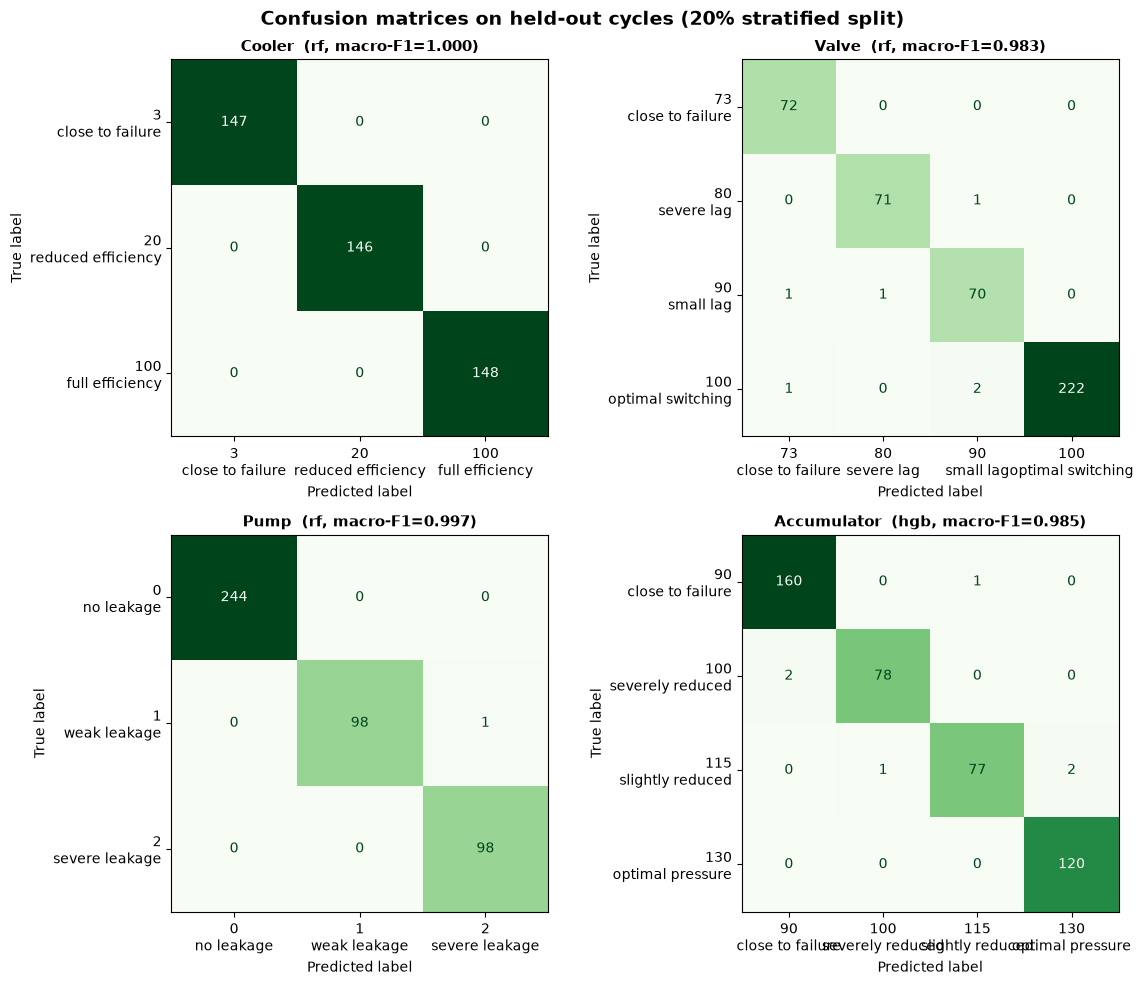

In [3]:
winners = {}
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, t in zip(axes.ravel(), TARGETS):
    Xtr, Xte, ytr, yte = splits[t]
    # re-fit winner (rf won or tied everywhere in practice; pick by leaderboard)
    name = lb[lb.component == t].iloc[0]["model"]
    mk = (lambda: RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)) \
        if name == "rf" else (lambda: HistGradientBoostingClassifier(random_state=42))
    m = mk().fit(Xtr, ytr)
    winners[t] = (name, m)
    pred = m.predict(Xte)
    classes = sorted(np.unique(yte))
    disp_labels = [f"{c}\n{TARGET_LABELS[t][c]}" for c in classes]
    ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=disp_labels) \
        .plot(ax=ax, cmap="Greens", colorbar=False, values_format="d")
    ax.set_title(f"{t.capitalize()}  ({name}, macro-F1="
                f"{lb[lb.component==t].iloc[0]['macro_f1']:.3f})",
                fontsize=11, fontweight="bold")
fig.suptitle("Confusion matrices on held-out cycles (20% stratified split)",
             fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG}/03_confusion_matrices.png", dpi=120)
plt.show()


## 3. Per-class report card

Macro-F1 summarizes, but a maintenance planner needs the per-state detail: *precision* (when we raise a flag, how often are we right?) and *recall* (of all real faults, how many did we catch?) for every health state.

In [4]:
from sklearn.metrics import classification_report
for t in TARGETS:
    name, m = winners[t]
    Xtr, Xte, ytr, yte = splits[t]
    labels = sorted(np.unique(yte))
    print(f"--- {t}  [{name}] ---")
    print(classification_report(
        yte, m.predict(Xte),
        target_names=[f"{c} ({TARGET_LABELS[t][c]})" for c in labels],
        digits=3))

--- cooler  [rf] ---
                         precision    recall  f1-score   support

   3 (close to failure)      1.000     1.000     1.000       147
20 (reduced efficiency)      1.000     1.000     1.000       146
  100 (full efficiency)      1.000     1.000     1.000       148

               accuracy                          1.000       441
              macro avg      1.000     1.000     1.000       441
           weighted avg      1.000     1.000     1.000       441

--- valve  [rf] ---
                         precision    recall  f1-score   support

  73 (close to failure)      0.973     1.000     0.986        72
        80 (severe lag)      0.986     0.986     0.986        72
         90 (small lag)      0.959     0.972     0.966        72
100 (optimal switching)      1.000     0.987     0.993       225

               accuracy                          0.986       441
              macro avg      0.979     0.986     0.983       441
           weighted avg      0.987     0.986

                    precision    recall  f1-score   support

    0 (no leakage)      1.000     1.000     1.000       244
  1 (weak leakage)      1.000     0.990     0.995        99
2 (severe leakage)      0.990     1.000     0.995        98

          accuracy                          0.998       441
         macro avg      0.997     0.997     0.997       441
      weighted avg      0.998     0.998     0.998       441

--- accumulator  [hgb] ---
                        precision    recall  f1-score   support

 90 (close to failure)      0.988     0.994     0.991       161
100 (severely reduced)      0.987     0.975     0.981        80
115 (slightly reduced)      0.987     0.963     0.975        80
130 (optimal pressure)      0.984     1.000     0.992       120

              accuracy                          0.986       441
             macro avg      0.986     0.983     0.985       441
          weighted avg      0.986     0.986     0.986       441



## 6. Which sensors matter? — the product insight

Feature importance aggregated back to the *sensor* level tells an asset manager where to invest in instrumentation: if temperature sensors dominate cooler prediction, a cheaper temperature-only retrofit may suffice. (Importance is taken from the random-forest model — the interpretable member of the comparison.)


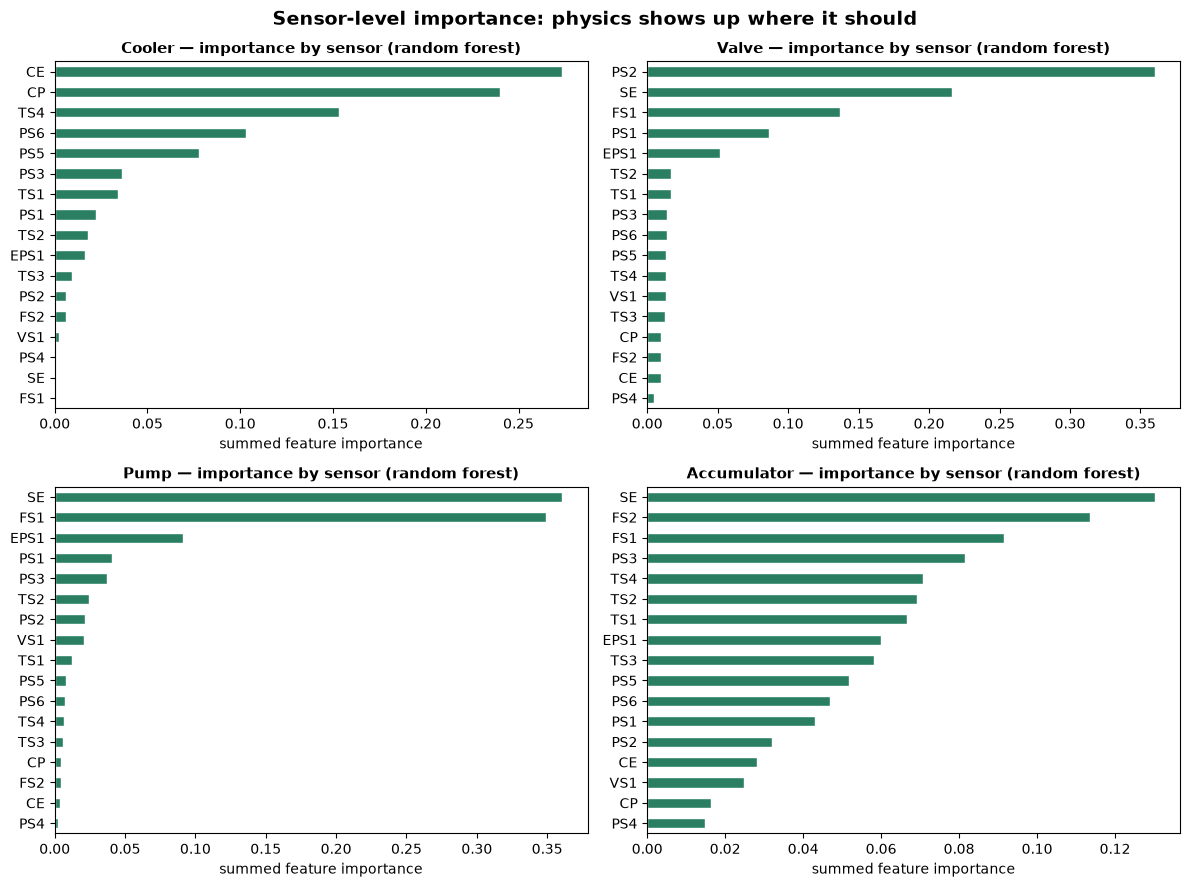

Top-3 sensors per component:
  cooler      : ['CE', 'CP', 'TS4']
  valve       : ['PS2', 'SE', 'FS1']
  pump        : ['SE', 'FS1', 'EPS1']
  accumulator : ['SE', 'FS2', 'FS1']


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sensor_rank = {}
for ax, t in zip(axes.ravel(), TARGETS):
    Xtr, Xte, ytr, yte = splits[t]
    m = RandomForestClassifier(n_estimators=300, n_jobs=-1,
                               random_state=42).fit(Xtr, ytr)
    imp = pd.Series(m.feature_importances_, index=X.columns)
    by_sensor = imp.groupby(imp.index.map(sensor_of)).sum().sort_values(ascending=True)
    sensor_rank[t] = by_sensor
    by_sensor.plot.barh(ax=ax, color="#2a7f62", edgecolor="white")
    ax.set_title(f"{t.capitalize()} — importance by sensor (random forest)",
                fontsize=11, fontweight="bold")
    ax.set_xlabel("summed feature importance")
fig.suptitle("Sensor-level importance: physics shows up where it should",
             fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG}/04_sensor_importance.png", dpi=120)
plt.show()

print("Top-3 sensors per component:")
for t in TARGETS:
    print(f"  {t:12s}: {list(sensor_rank[t].tail(3).index[::-1])}")


## 4. Prediction walkthrough: real held-out cycles

Scores are abstract — let's look at actual cycles. For two components we show correctly classified cycles (with the sensor evidence) and misclassified ones, comparing each cycle's top-3 feature values against the class means. This is how you'd debug a model with a domain engineer.

In [6]:
print("=== prediction walkthrough ===\n")
for t in ["cooler", "valve"]:
    name, m = winners[t]
    Xtr, Xte, ytr, yte = splits[t]
    pred = m.predict(Xte)
    idx = np.arange(len(y))
    _, te_idx = train_test_split(idx, test_size=0.2, random_state=42,
                                 stratify=y[t].values)
    rf = RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                random_state=42).fit(Xtr, ytr)
    imp3 = pd.Series(rf.feature_importances_, index=X.columns).nlargest(3)
    ok = pred == yte
    show = []
    for cls in sorted(np.unique(yte)):
        ii = np.where(ok & (yte == cls))[0]
        if len(ii):
            show.append(("correct", ii[0]))
        if len(show) == 2:
            break
    for j in np.where(~ok)[0][:2]:
        show.append(("WRONG", j))
    print(f"--- {t} ---")
    for kind, j in show:
        mark = "✓" if kind == "correct" else "✗ MISCLASSIFIED"
        print(f"cycle {te_idx[j]:4d} | true={yte[j]:3d} ({TARGET_LABELS[t][yte[j]]})"
              f" -> pred={pred[j]:3d} ({TARGET_LABELS[t][pred[j]]})  {mark}")
        for f in imp3.index:
            cms = "  ".join(f"{c}:{X[y[t].values == c][f].mean():.1f}"
                           for c in sorted(np.unique(yte)))
            print(f"    {f:12s} cycle={Xte.iloc[j][f]:8.1f}   class means -> {cms}")
        print()

=== prediction walkthrough ===



--- cooler ---
cycle  166 | true=  3 (close to failure) -> pred=  3 (close to failure)  ✓
    CE_mean      cycle=    19.6   class means -> 3:19.6  20:27.2  100:46.9
    CE_max       cycle=    20.2   class means -> 3:20.1  20:27.8  100:47.5
    CE_median    cycle=    19.6   class means -> 3:19.6  20:27.2  100:46.9

cycle  734 | true= 20 (reduced efficiency) -> pred= 20 (reduced efficiency)  ✓
    CE_mean      cycle=    27.9   class means -> 3:19.6  20:27.2  100:46.9
    CE_max       cycle=    28.4   class means -> 3:20.1  20:27.8  100:47.5
    CE_median    cycle=    27.9   class means -> 3:19.6  20:27.2  100:46.9



--- valve ---
cycle  619 | true= 73 (close to failure) -> pred= 73 (close to failure)  ✓
    PS2_kurt     cycle=     0.5   class means -> 73:1.2  80:1.3  90:1.3  100:1.5
    PS2_skew     cycle=    -1.4   class means -> 73:-1.7  80:-1.7  90:-1.8  100:-1.8
    SE_skew      cycle=     0.7   class means -> 73:-1.4  80:-1.6  90:-1.6  100:-1.9

cycle 1227 | true= 80 (severe lag) -> pred= 80 (severe lag)  ✓
    PS2_kurt     cycle=     1.4   class means -> 73:1.2  80:1.3  90:1.3  100:1.5
    PS2_skew     cycle=    -1.8   class means -> 73:-1.7  80:-1.7  90:-1.8  100:-1.8
    SE_skew      cycle=    -2.0   class means -> 73:-1.4  80:-1.6  90:-1.6  100:-1.9

cycle  621 | true= 80 (severe lag) -> pred= 90 (small lag)  ✗ MISCLASSIFIED
    PS2_kurt     cycle=     0.8   class means -> 73:1.2  80:1.3  90:1.3  100:1.5
    PS2_skew     cycle=    -1.6   class means -> 73:-1.7  80:-1.7  90:-1.8  100:-1.8
    SE_skew      cycle=     1.5   class means -> 73:-1.4  80:-1.6  90:-1.6  100:-1.9

cycle  380 | tru

## 5. Top individual features

Section 3 showed *sensor*-level importance (good for instrumentation budgets). Here is the *feature*-level view — useful when an engineer asks exactly which statistic the model leans on.

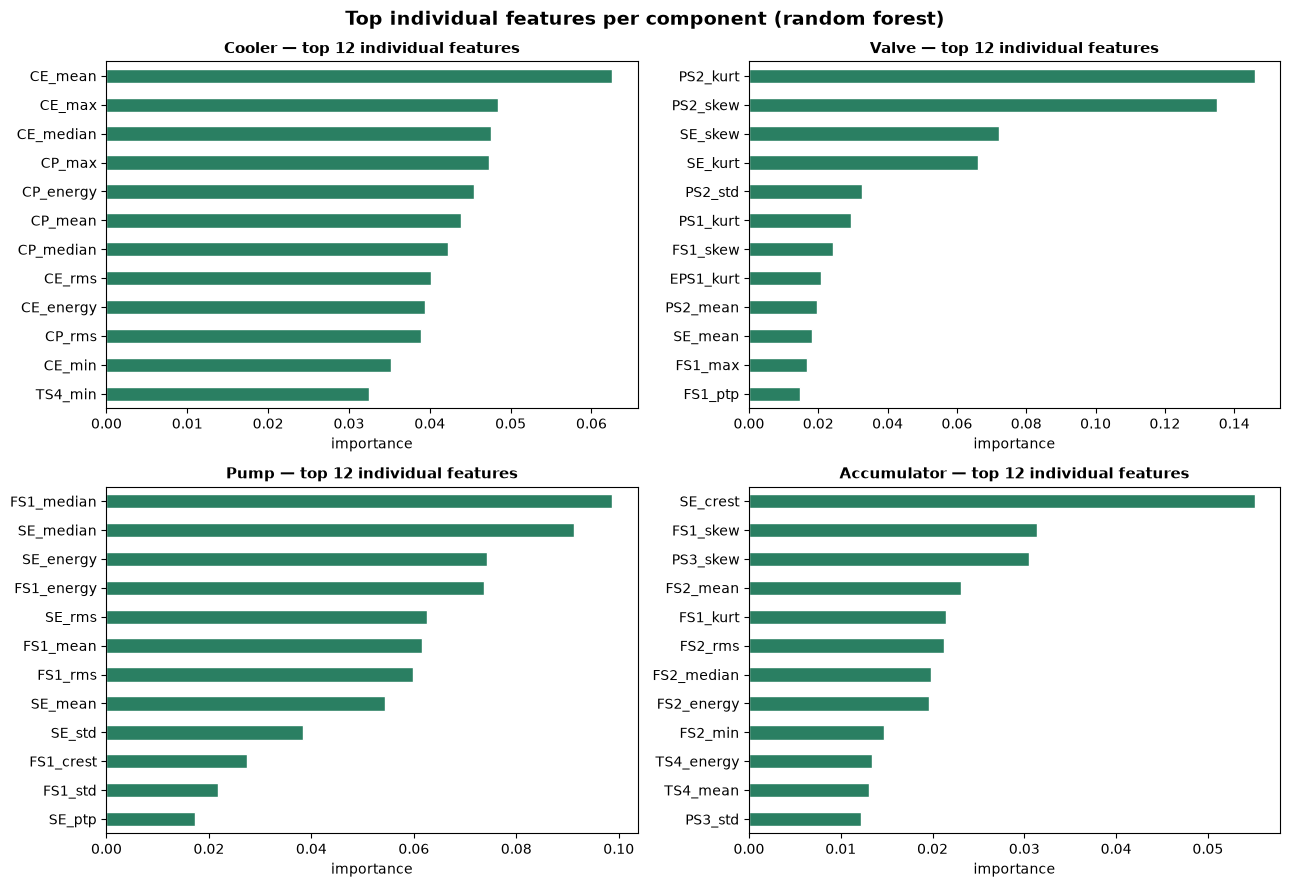

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, t in zip(axes.ravel(), TARGETS):
    Xtr, Xte, ytr, yte = splits[t]
    m = RandomForestClassifier(n_estimators=300, n_jobs=-1,
                               random_state=42).fit(Xtr, ytr)
    top = pd.Series(m.feature_importances_, index=X.columns).nlargest(12).sort_values()
    top.plot.barh(ax=ax, color="#2a7f62", edgecolor="white")
    ax.set_title(f"{t.capitalize()} — top 12 individual features",
                 fontweight="bold", fontsize=11)
    ax.set_xlabel("importance")
fig.suptitle("Top individual features per component (random forest)",
             fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG}/10_top_features.png", dpi=120)
plt.show()

## 7. Results, limitations, next steps

**What we can claim.** Per-cycle statistical features + off-the-shelf tree ensembles separate all four component health states on held-out cycles (see scores above). Sensor importance aligns with physics: temperature sensors dominate cooler state, pressure sensors dominate valve state — the model rediscovers the engineering.

**Limitations (stated plainly).**
- Test-rig data, not field data: real plants add sensor drift, missing data, and mixed fault modes.
- One fixed 60 s cycle framing; a streaming deployment would need windowing + latency analysis.
- Single stratified split with a fixed seed — reported scores are indicative, not a full cross-validation study.

**Next steps.**
- Add spectral (FFT-band) features for the 100 Hz pressure/power signals.
- Try sequence models (1D-CNN/LSTM) on raw signals vs. the feature baseline.
- Feed these predictions into a **maintenance decision engine** (cost of downtime vs. cost of intervention) — the subject of Project #3 in this portfolio.


In [8]:
# persist a machine-readable summary for the README / dashboard
summary = {}
for _, r in lb.iterrows():
    summary.setdefault(r["component"], {})[r["model"]] = {
        "accuracy": r["accuracy"], "macro_f1": r["macro_f1"]}
with open("../reports/metrics.json", "w") as f:
    json.dump({"leaderboard": summary,
               "n_cycles": int(len(y)),
               "n_features": int(X.shape[1])}, f, indent=2)
print(open("../reports/metrics.json").read())


{
  "leaderboard": {
    "accumulator": {
      "hgb": {
        "accuracy": 0.9864,
        "macro_f1": 0.9846
      },
      "rf": {
        "accuracy": 0.9796,
        "macro_f1": 0.9777
      }
    },
    "cooler": {
      "rf": {
        "accuracy": 1.0,
        "macro_f1": 1.0
      },
      "hgb": {
        "accuracy": 1.0,
        "macro_f1": 1.0
      }
    },
    "pump": {
      "rf": {
        "accuracy": 0.9977,
        "macro_f1": 0.9966
      },
      "hgb": {
        "accuracy": 0.9955,
        "macro_f1": 0.9932
      }
    },
    "valve": {
      "rf": {
        "accuracy": 0.9864,
        "macro_f1": 0.9828
      },
      "hgb": {
        "accuracy": 0.9841,
        "macro_f1": 0.9794
      }
    }
  },
  "n_cycles": 2205,
  "n_features": 187
}
